MEMBER A

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("cat.png")
avg_gray = img.mean(axis=2).astype(np.uint8)
weighted_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

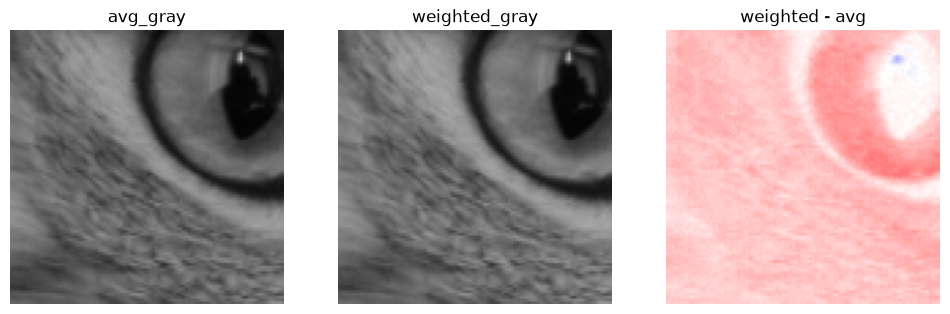

avg_gray:
 [[ 74  82  92 ...  27  28  28]
 [ 77  78  87 ...  26  25  26]
 [ 79  77  84 ...  23  23  25]
 ...
 [ 81  79  81 ... 111 116 119]
 [ 92  87  87 ... 107 107 101]
 [103 101 101 ... 142 141 132]]
weighted_gray:
 [[ 79  88  99 ...  31  33  33]
 [ 82  84  93 ...  31  30  31]
 [ 85  83  90 ...  28  29  30]
 ...
 [ 88  85  87 ... 120 126 128]
 [ 98  93  94 ... 115 115 109]
 [109 107 107 ... 149 147 138]]
difference:
 [[ 5  6  7 ...  4  5  5]
 [ 5  6  6 ...  5  5  5]
 [ 6  6  6 ...  5  6  5]
 ...
 [ 7  6  6 ...  9 10  9]
 [ 6  6  7 ...  8  8  8]
 [ 6  6  6 ...  7  6  6]]
mean abs diff: 6.9902  max: 16


In [6]:
# pick a small region (rows y0:y1, cols x0:x1)
y0, x0, size = 100, 100, 100
a = avg_gray[y0:y0+size, x0:x0+size]
w = weighted_gray[y0:y0+size, x0:x0+size]

# cast to int first: uint8 subtraction wraps around (3 - 5 = 254)
diff = w.astype(int) - a.astype(int)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(a, cmap="gray", vmin=0, vmax=255); ax[0].set_title("avg_gray")
ax[1].imshow(w, cmap="gray", vmin=0, vmax=255); ax[1].set_title("weighted_gray")
ax[2].imshow(diff, cmap="bwr", vmin=-30, vmax=30); ax[2].set_title("weighted - avg")
for axis in ax: axis.axis("off")
plt.show()

print("avg_gray:\n", a)
print("weighted_gray:\n", w)
print("difference:\n", diff)
print("mean abs diff:", np.abs(diff).mean(), " max:", np.abs(diff).max())

Member B

In [9]:
def convert_bits(img,b):
    step = 255 / (2**b - 1)
    index = np.round(img / step)
    recon = index * step
    return recon

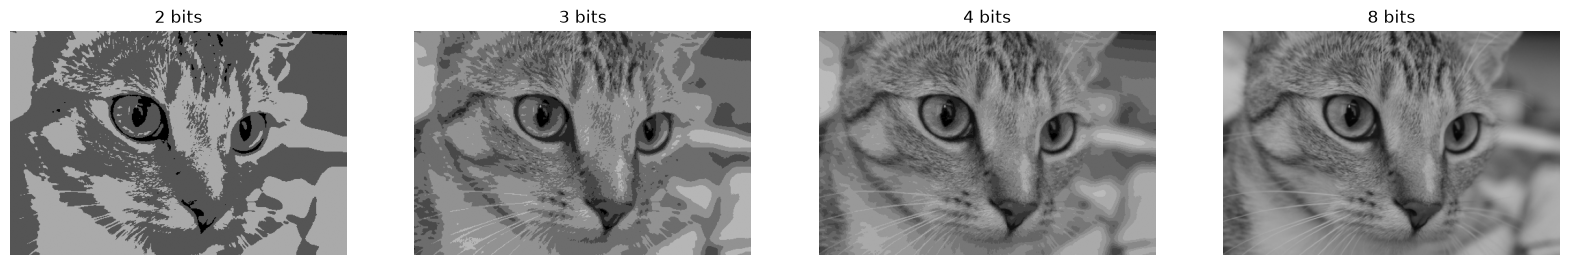

In [26]:
bits2_img = convert_bits(weighted_gray, 2)
bits3_img = convert_bits(weighted_gray, 3)
bits4_img = convert_bits(weighted_gray, 4)

fig, ax = plt.subplots(1, 4, figsize=(20,10))
ax[0].imshow(bits2_img, cmap="gray", vmin=0, vmax=255); ax[0].set_title("2 bits")
ax[1].imshow(bits3_img, cmap="gray", vmin=0, vmax=255); ax[1].set_title("3 bits")
ax[2].imshow(bits4_img, cmap="gray", vmin=0, vmax=255); ax[2].set_title("4 bits")
ax[3].imshow(weighted_gray, cmap="gray", vmin=0, vmax=255); ax[3].set_title("8 bits")
for axis in ax: axis.axis("off")
plt.show()

MEMBER C

In [35]:
def mean_abs_err(img):
    return np.abs(weighted_gray.astype(int) - img.astype(int)).mean()

In [39]:
IMAGE = [bits2_img, bits3_img, bits4_img]
mae = [mean_abs_err(i) for i in IMAGE]

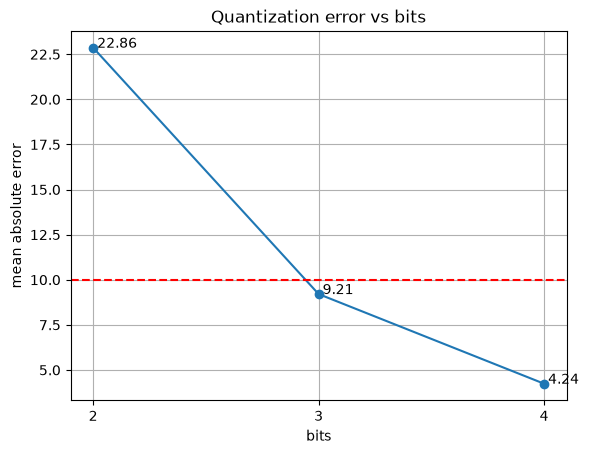

In [52]:
bits = [2, 3, 4]

plt.plot(bits, mae, "o-")          # "o-" = dots joined by a line
for b, e in zip(bits, mae):
    plt.text(b, e, f" {e:.2f}")    # write the value next to each dot
plt.xticks(bits)                   # show only 2, 3, 4 on the x-axis
plt.xlabel("bits")
plt.axhline(y=10, color="red", linestyle="--", label="threshold = 10")
plt.ylabel("mean absolute error")
plt.title("Quantization error vs bits")
plt.grid(True)
plt.show()

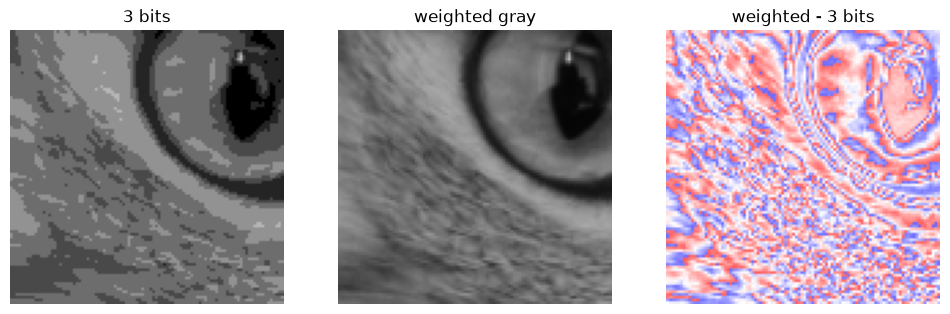

In [57]:
y0, x0, size = 100, 100, 100
bits3 = bits3_img[y0:y0+size, x0:x0+size]
w = weighted_gray[y0:y0+size, x0:x0+size]

diff = w.astype(int) - bits3.astype(int)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(bits3, cmap="gray", vmin=0, vmax=255); ax[0].set_title("3 bits")
ax[1].imshow(w, cmap="gray", vmin=0, vmax=255); ax[1].set_title("weighted gray")
ax[2].imshow(diff, cmap="bwr", vmin=-30, vmax=30); ax[2].set_title("weighted - 3 bits")
for axis in ax: axis.axis("off")
plt.show()